### 

In [1]:
from StochasticCliffWalking import StochasticCliffWalkingEnv
from episode_generator import generate_episode
from tqdm import tqdm

import matplotlib.pyplot as plt
import numpy as np

In [2]:
def epsilon_soft_policy(Q, nA, epsilon=0.1):
    def policy(state):
        action_probilities = np.full(nA, epsilon/nA)
        action_probilities[np.argmax(Q[state])] += 1 - epsilon
        return action_probilities
    return policy

In [3]:
def first_visit_monte_carlo_epsilon_soft(env, epsilon, gamma = 0.99, episods = 5000):
    Q = np.zeros((env.nS,env.nA))

    returns = {}
    for state in range(env.nS):
        returns[state] = []
        for _ in range(env.nA):
            returns[state].append({
                'sum': 0,
                'count': 0,
            })
    
    return_history = []
    
    for _ in tqdm(range(episods)):
        policy = epsilon_soft_policy(Q, env.nA, epsilon)

        states, actions, rewards = generate_episode(policy, env)

        G = 0
        return_values = [0] * len(states)

        for t in reversed(range(len(states))):
            state = states[t]
            action = actions[t]
            reward = rewards[t]

            G = gamma * G + reward
            return_values[t] = G

        visted_state_actions = set()
        for t in range(len(states)):
            state = states[t]
            action = actions[t]


            if (state, action) not in visted_state_actions:
                visted_state_actions.add((state,action))

                returns[state][action]['sum'] += return_values[t]
                returns[state][action]['count'] += 1

                Q[state][action] = returns[state][action]['sum']/returns[state][action]['count']

        return_history.append(G)

    return Q, policy, return_history

In [5]:
env = StochasticCliffWalkingEnv()
Q_epsilon_01, policy_epsilon_01, ـ = first_visit_monte_carlo_epsilon_soft(env, 0.1, episods=7000)
Q_epsilon_001, policy_epsilon_001, ـ = first_visit_monte_carlo_epsilon_soft(env, 0.01, episods=7000)

100%|██████████| 7000/7000 [00:35<00:00, 199.06it/s]


In [20]:
def mc_run_path(Q, env, render=True, max_length=50, mode="human"):
    state = env.reset()[0]

    total_reward = 0
    path = [state]
    terminated = False

    step_count = 0

    if render:
        env.render(mode)

    while not terminated:
        selected_action = np.argmax(Q[state])
        next_state, reward, terminated, _, _ =env.step(selected_action)

        path.append(next_state)
        state = next_state
        total_reward += reward

        if render:
            env.render(mode)

        step_count += 1

        if step_count > max_length:
            break
        
    env.close()

    return path

states_epsilon_01 = mc_run_path(Q_epsilon_01, env)

states_epsilon_001 = mc_run_path(Q_epsilon_001,env)

print(f"Path for policy with epsilon = 0.1 : \n{states_epsilon_01}\n\
        Path for policy with epsilon = 0.01 : \n{states_epsilon_001}")


FFFFFFFFFFFF
FFFFFFFFFFFF
FFFFFFFFFFFF
SCCCCCCCCCCG
  (Up)
FFFFFFFFFFFF
FFFFFFFFFFFF
FFFFFFFFFFFF
SCCCCCCCCCCG
  (Up)
FFFFFFFFFFFF
FFFFFFFFFFFF
FFFFFFFFFFFF
SCCCCCCCCCCG
  (Up)
FFFFFFFFFFFF
FFFFFFFFFFFF
FFFFFFFFFFFF
SCCCCCCCCCCG
  (Right)
FFFFFFFFFFFF
FFFFFFFFFFFF
FFFFFFFFFFFF
SCCCCCCCCCCG
  (Right)
FFFFFFFFFFFF
FFFFFFFFFFFF
FFFFFFFFFFFF
SCCCCCCCCCCG
  (Right)
FFFFFFFFFFFF
FFFFFFFFFFFF
FFFFFFFFFFFF
SCCCCCCCCCCG
  (Right)
FFFFFFFFFFFF
FFFFFFFFFFFF
FFFFFFFFFFFF
SCCCCCCCCCCG
  (Right)
FFFFFFFFFFFF
FFFFFFFFFFFF
FFFFFFFFFFFF
SCCCCCCCCCCG
  (Right)
FFFFFFFFFFFF
FFFFFFFFFFFF
FFFFFFFFFFFF
SCCCCCCCCCCG
  (Down)
FFFFFFFFFFFF
FFFFFFFFFFFF
FFFFFFFFFFFF
SCCCCCCCCCCG
  (Right)
FFFFFFFFFFFF
FFFFFFFFFFFF
FFFFFFFFFFFF
SCCCCCCCCCCG
  (Down)
FFFFFFFFFFFF
FFFFFFFFFFFF
FFFFFFFFFFFF
SCCCCCCCCCCG
  (Right)
FFFFFFFFFFFF
FFFFFFFFFFFF
FFFFFFFFFFFF
SCCCCCCCCCCG
  (Up)
FFFFFFFFFFFF
FFFFFFFFFFFF
FFFFFFFFFFFF
SCCCCCCCCCCG
  (Up)
FFFFFFFFFFFF
FFFFFFFFFFFF
FFFFFFFFFFFF
SCCCCCCCCCCG
  (Up)
FFFFFFFFFFFF
FFFFFFFFFFFF
F

100%|██████████| 5000/5000 [00:19<00:00, 254.50it/s]


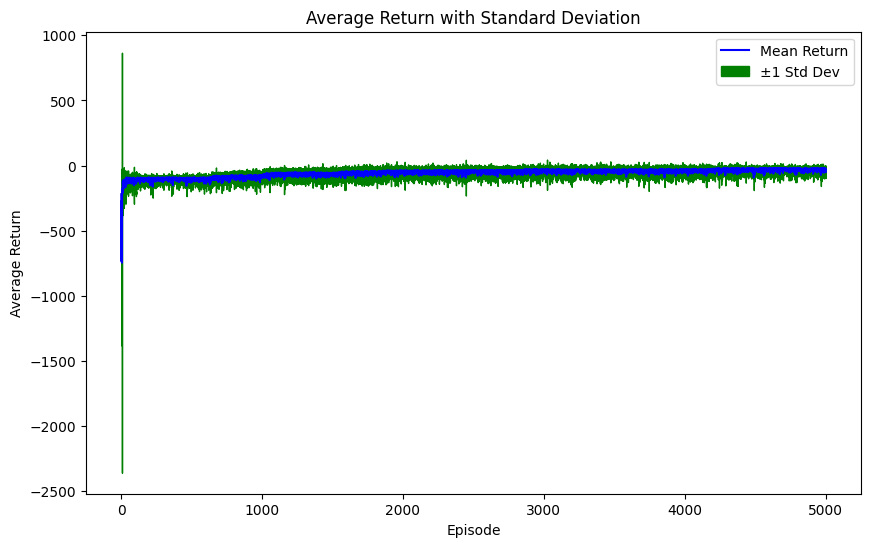

In [ ]:
def plot_mean_std(histories):
    mean_returns = np.mean(histories, axis=0)
    std_returns = np.std(histories, axis=0)
    episodes = np.arange(1, len(mean_returns) + 1)

    plt.figure(figsize=(10, 6))
    plt.plot(episodes, mean_returns, label='Mean Return', color='b')
    plt.fill_between(episodes, mean_returns - std_returns, 
                     mean_returns + std_returns, color='g', label='±1 Std Dev')
    plt.xlabel('Episode')
    plt.ylabel('Average Return')
    plt.title('Average Return with Standard Deviation')
    plt.legend()
    plt.savefig("homework-1-1.png")
    plt.show()


runs = 10
run_histories = []

for i in range(runs):
    _, _, history = first_visit_monte_carlo_epsilon_soft(env, 0.1)
    run_histories.append(history)

plot_mean_std(run_histories)

In [6]:
def behavior_policy(nA):
    # input parameter is just for use same structure as other policies
    def policy(_):
        return np.full(nA, 1/nA)
    return policy

def target_policy(Q, nA):
    def policy(state):
        action_probilities = np.zeros(nA)
        action_probilities[np.argmax(Q[state])] = 1
        return action_probilities
    return policy

In [13]:
def incremental_ordinary_importance_sampling(env, Q_target, policy_func, episodes = 10000, gamma = 0.99):
    Q = np.zeros((env.nS, env.nA))
    N = np.zeros((env.nS, env.nA))

    target_states = [36, 29, 5]
    V_history = {s: [] for s in target_states}

    for _ in tqdm(range(episodes)):
        env.reset()

        pi_policy = policy_func(Q_target ,env.nA)
        b_policy = behavior_policy(env.nA)

        states, actions, rewards = generate_episode(b_policy, env)

        G = 0
        rho = 1

        for t in reversed(range(len(states))):
            state = states[t]
            action = actions[t]
            reward = rewards[t]

            G = gamma * G + reward
            
            pi = pi_policy(state)[action]
            b = b_policy(state)[action]

            if b == 0:
                rho = 0
                break

            rho *= pi/b
            
            if rho == 0:
                break
        
            N[state][action] += 1
            Q[state][action] += (rho * G - Q[state][action]) / N[state][action]
        
        for s in target_states:
            V_history[s].append(np.max(Q[s]))
    
    return Q, V_history

Q_ordinary_importance_sampling, history_ois = incremental_ordinary_importance_sampling(env, Q_epsilon_01, target_policy)

100%|██████████| 10000/10000 [01:08<00:00, 146.82it/s]


In [24]:
def incremental_weighted_importance_sampling(env, Q_target, policy_func, episodes = 10000, gamma = 0.99):
    Q = np.zeros((env.nS, env.nA))
    C = np.zeros((env.nS, env.nA))

    target_states = [36, 29, 5]
    V_history = {s: [] for s in target_states}

    for _ in tqdm(range(episodes)):
        env.reset()

        pi_policy = policy_func(Q_target,env.nA)
        b_policy = behavior_policy(env.nA)

        states, actions, rewards = generate_episode(b_policy, env)

        G = 0
        rho = 1

        for t in reversed(range(len(states))):
            state = states[t]
            action = actions[t]
            reward = rewards[t]

            G = gamma * G + reward
            
            pi = pi_policy(state)[action]
            b = b_policy(state)[action]

            if b == 0:
                rho = 0
                break

            rho *= pi/b
            
            if rho == 0:
                break
        
            C[state][action] += rho
            if C[state][action] > 0:
                Q[state][action] += (rho * (G - Q[state][action])) / C[state][action]
        
        for s in target_states:
            V_history[s].append(np.max(Q[s]))
    
    return Q, V_history

Q_weighted_importance_sampling, history_wis = incremental_weighted_importance_sampling(env, Q_epsilon_01, target_policy)

100%|██████████| 10000/10000 [00:59<00:00, 167.25it/s]


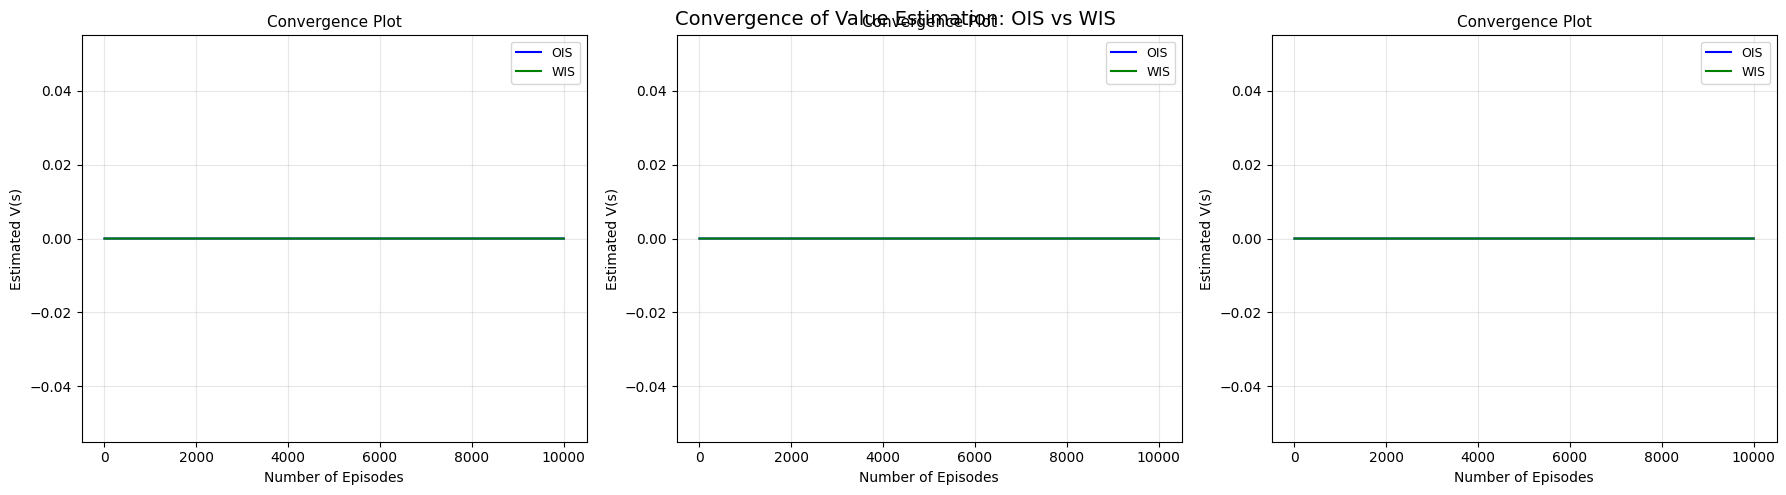

In [25]:
def plot_value_coverage(history_ois, history_wis, fig_name):
    epsode_len = len(history_ois[36])
    episodes = np.arange(1, epsode_len + 1)

    _, axes = plt.subplots(1, 3, figsize=(18, 5))

    for idx, (state_key, _) in enumerate(history_ois.items()):
        ois_vals = np.array(history_ois[state_key])
        wis_vals = np.array(history_wis[state_key])

        axes[idx].plot(episodes, ois_vals, 'b-', label='OIS', linewidth=1.5)
        axes[idx].plot(episodes, wis_vals, 'g-', label='WIS', linewidth=1.5)
        axes[idx].set_xlabel('Number of Episodes', fontsize=10)
        axes[idx].set_ylabel('Estimated V(s)', fontsize=10)
        axes[idx].set_title("Convergence Plot", fontsize=11)
        axes[idx].legend(fontsize=9)
        axes[idx].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.suptitle('Convergence of Value Estimation: OIS vs WIS', 
                fontsize=14)
    plt.savefig(fig_name)
    plt.show()

plot_value_coverage(history_ois, history_wis, "homeword-1-2.png")

100%|██████████| 10000/10000 [01:15<00:00, 132.48it/s]


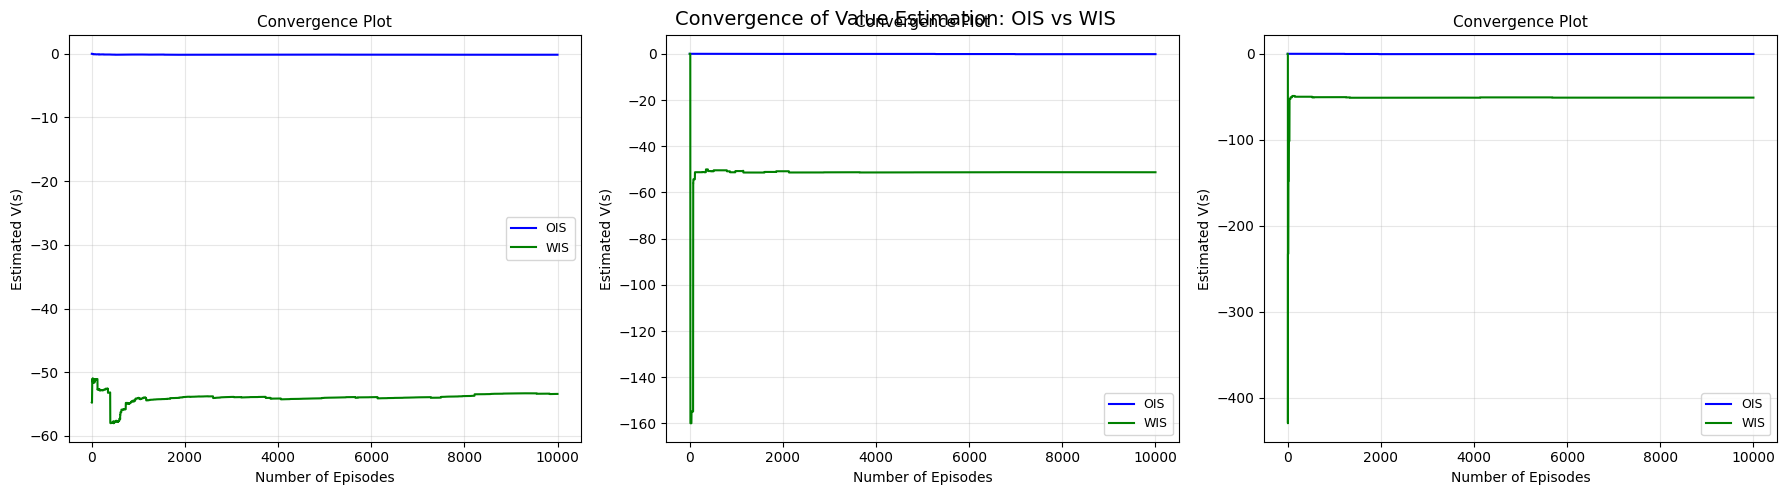

In [ ]:
Q_ois_greedy, history_ois_epsilon_greedy = incremental_ordinary_importance_sampling(env, Q_epsilon_01, epsilon_soft_policy)
Q_wis_greedy, history_wis_epsilon_greedy = incremental_weighted_importance_sampling(env, Q_epsilon_01, epsilon_soft_policy)

plot_value_coverage(history_ois_epsilon_greedy, history_wis_epsilon_greedy, "homeword-1-3.png")